# Sustainable Fertilizer Usage Optimizer (SIH1639)
Register number: URK24CS9046

This notebook covers EDA, crop-recommendation modeling, and the rice fertilizer dose, cost and saving analysis.
Run it from the `notebooks` folder. It reads the files created by the scripts in `src/` (from `../data`).

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, ConfusionMatrixDisplay

soil = pd.read_csv("../data/soil_labeled.csv")
rice = pd.read_csv("../data/rice_final.csv")
prices = pd.read_csv("../data/fertilizer_prices.csv")
print(soil.shape, rice.shape)
soil.head()

(2200, 12) (100, 20)


,N,P,K,temperature,humidity,ph,rainfall,label,N_level,P_level,K_level,pH_class
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice,High,Medium,Medium,Neutral
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice,High,Medium,Medium,Neutral
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice,Medium,Medium,Medium,Alkaline
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice,High,Low,Medium,Neutral
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice,High,Medium,Medium,Alkaline


## 1. Data check

In [2]:
print("Missing values:", int(soil.isna().sum().sum()))
print("Duplicate rows:", int(soil.duplicated().sum()))
print(soil["label"].value_counts().head())
soil.describe().round(1)

Missing values: 0
Duplicate rows: 0
label
rice           100
maize          100
chickpea       100
kidneybeans    100
pigeonpeas     100
Name: count, dtype: int64


,N,P,K,temperature,humidity,ph,rainfall
count,2200.0,2200.0,2200.0,2200.0,2200.0,2200.0,2200.0
mean,50.6,53.4,48.1,25.6,71.5,6.5,103.5
std,36.9,33.0,50.6,5.1,22.3,0.8,55.0
min,0.0,5.0,5.0,8.8,14.3,3.5,20.2
25%,21.0,28.0,20.0,22.8,60.3,6.0,64.6
50%,37.0,51.0,32.0,25.6,80.5,6.4,94.9
75%,84.2,68.0,49.0,28.6,89.9,6.9,124.3
max,140.0,145.0,205.0,43.7,100.0,9.9,298.6


## 2. Fertilizer prices (Lok Sabha Unstarred Question No. 878, 26 July 2024, Tamil Nadu 2023-24)

In [3]:
prices

,fertilizer,bag_kg,price_per_bag_inr,N_pct,P2O5_pct,K2O_pct,price_per_kg_inr,cost_per_kg_main_nutrient_inr,source
0,Urea,45,242.00,46,0,0,5.38,11.70,Lok Sabha reply AU878 (eparlib.nic.in)
1,DAP,50,1331.26,18,46,0,26.63,57.89,Lok Sabha reply AU878 (eparlib.nic.in)
2,MOP,50,1661.24,0,0,60,33.22,55.37,Lok Sabha reply AU878 (eparlib.nic.in)
3,SSP,50,531.66,0,16,0,10.63,66.44,Lok Sabha reply AU878 (eparlib.nic.in)


## 3. EDA

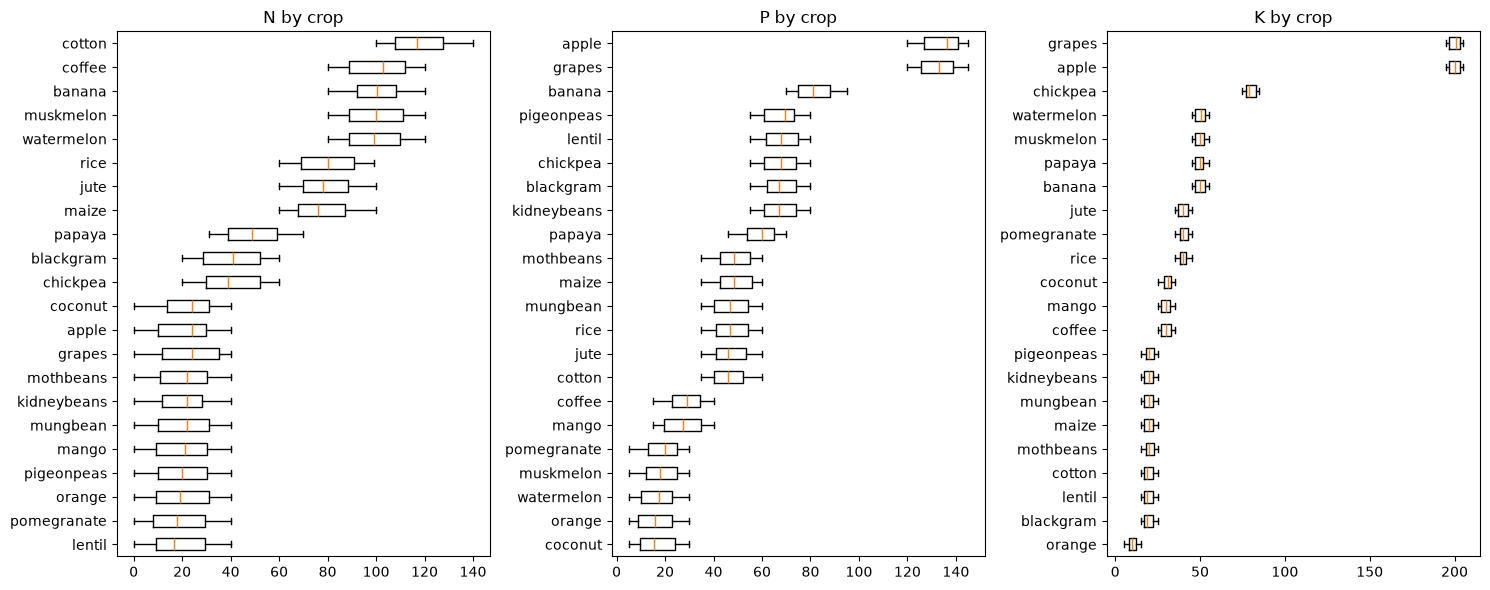

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 6))
for ax, col in zip(axes, ["N", "P", "K"]):
    order = soil.groupby("label")[col].median().sort_values().index
    data = [soil[soil["label"] == c][col] for c in order]
    ax.boxplot(data, tick_labels=order, orientation="horizontal")
    ax.set_title(col + " by crop")
plt.tight_layout()
plt.show()

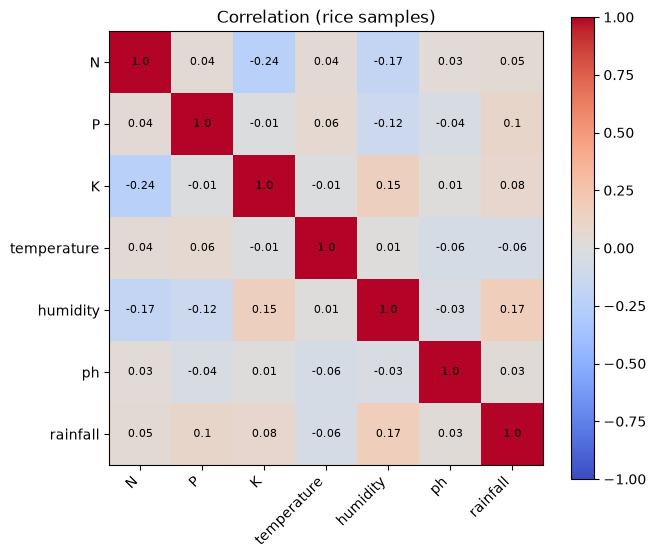

In [5]:
cols = ["N", "P", "K", "temperature", "humidity", "ph", "rainfall"]
corr = rice[cols].corr()
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(cols))); ax.set_xticklabels(cols, rotation=45, ha="right")
ax.set_yticks(range(len(cols))); ax.set_yticklabels(cols)
for i in range(len(cols)):
    for j in range(len(cols)):
        ax.text(j, i, round(corr.iloc[i, j], 2), ha="center", va="center", fontsize=8)
plt.colorbar(im)
ax.set_title("Correlation (rice samples)")
plt.show()

## 4. Crop recommendation model
22 crops, so chance accuracy is about 4.5%. Models are compared with 5-fold cross-validation on an 80/20 split.

In [6]:
features = cols
X, y = soil[features], soil["label"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
    "KNN": make_pipeline(StandardScaler(), KNeighborsClassifier()),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42),
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
for name, model in models.items():
    s = cross_val_score(model, X_train, y_train, cv=cv)
    print(f"{name}: CV accuracy {s.mean():.3f} (+/- {s.std():.3f})")

Logistic Regression: CV accuracy 0.968 (+/- 0.007)
KNN: CV accuracy 0.965 (+/- 0.012)


Random Forest: CV accuracy 0.994 (+/- 0.005)


Test accuracy: 0.995
Test macro F1: 0.995


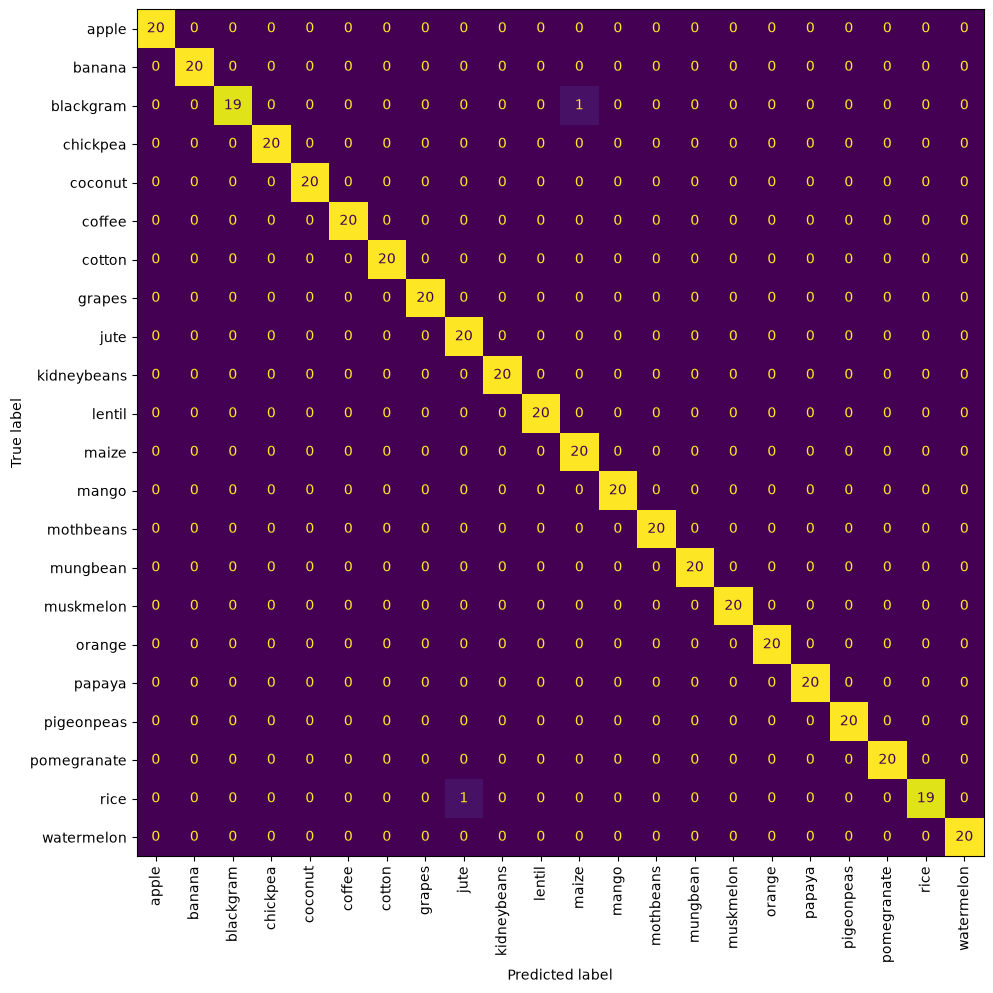

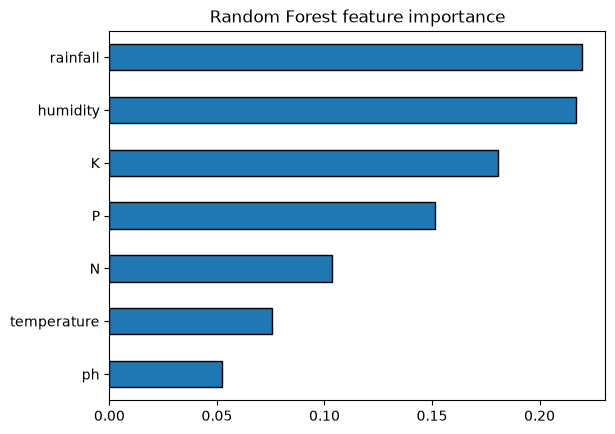

In [7]:
best = models["Random Forest"].fit(X_train, y_train)
pred = best.predict(X_test)
print("Test accuracy:", round(accuracy_score(y_test, pred), 3))
print("Test macro F1:", round(f1_score(y_test, pred, average="macro"), 3))

fig, ax = plt.subplots(figsize=(11, 11))
ConfusionMatrixDisplay.from_predictions(y_test, pred, ax=ax, xticks_rotation=90, colorbar=False)
plt.show()

imp = pd.Series(best.feature_importances_, index=features).sort_values()
imp.plot.barh(edgecolor="black", title="Random Forest feature importance")
plt.show()

## 5. Honest check: can rice P level be predicted without P?
If soil nutrients were predictable from weather, this would score well above chance (0.33).

In [8]:
Xr = rice[["N", "K", "temperature", "humidity", "ph", "rainfall"]]
yr = rice["P_level_rice"]
sr = cross_val_score(RandomForestClassifier(n_estimators=200, random_state=42), Xr, yr,
                     cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42))
print(f"CV accuracy {sr.mean():.3f} (chance = 0.33)")

CV accuracy 0.330 (chance = 0.33)


## 6. Rice dose, cost and saving
The dose is a **rule based on the TNAU range**, not a trained model: Low soil level gets the highest TNAU dose, Medium the median, High the lowest.
Baseline for savings is an assumption: every field gets the highest dose (Rs 6745 per ha).

Mean cost (Rs/ha): 4619
Mean saving (Rs/ha): 2126
Mean saving (%): 31.5


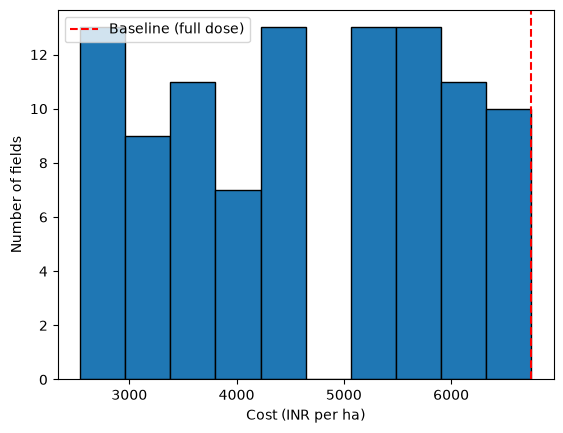

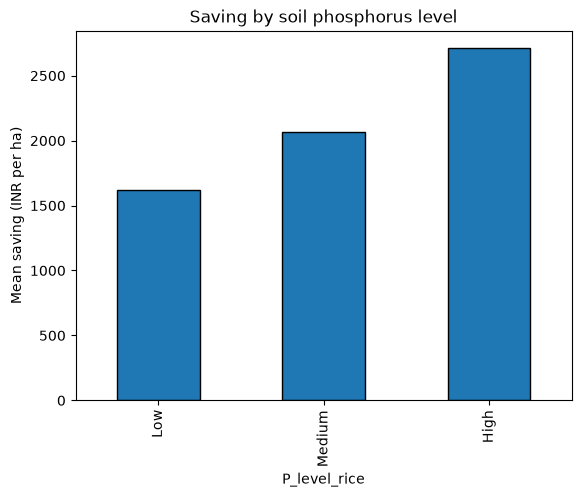

In [9]:
print("Mean cost (Rs/ha):", round(rice["cost_inr_per_ha"].mean()))
print("Mean saving (Rs/ha):", round(rice["saving_inr_per_ha"].mean()))
print("Mean saving (%):", round(rice["saving_pct"].mean(), 1))

plt.hist(rice["cost_inr_per_ha"], bins=10, edgecolor="black")
plt.axvline(6745, color="red", linestyle="--", label="Baseline (full dose)")
plt.xlabel("Cost (INR per ha)"); plt.ylabel("Number of fields"); plt.legend()
plt.show()

order = ["Low", "Medium", "High"]
rice.groupby("P_level_rice")["saving_inr_per_ha"].mean().reindex(order).plot.bar(edgecolor="black")
plt.ylabel("Mean saving (INR per ha)"); plt.title("Saving by soil phosphorus level")
plt.show()

## 7. Conclusions
- Random Forest recommends crops with about 99% accuracy on this very clean dataset (not field accuracy).
- Soil nutrients cannot be predicted from weather (33% = chance), so P and K doses need a soil test.
- The TNAU-range rule saves about Rs 2126 per hectare (31.5%) against the full-dose baseline.
- Limitations: Kaggle data is not from Tamil Nadu, nitrogen dose is not included, and the baseline is an assumption.